<a href="https://colab.research.google.com/github/MulkernHunter/INFO-4670/blob/main/Copy_of_INFO4670_Assignment_SMS_Spam_v4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 12: Assignment 4 — SMS Spam Detection

**Goal:** Apply the six-step classification workflow to a real dataset.
Predict whether an SMS message is spam or legitimate (ham) using text-based features.

---

## I. Assignment Objective

By completing this assignment, you will:
- Follow a complete classification pipeline on real-world data
- Engineer binary features from raw text
- Train and evaluate a Decision Tree and a Naive Bayes classifier
- Interpret a confusion matrix and choose the right evaluation metric
- Analyze model performance and reflect on possible improvements

---

## II. Dataset

**Source:** UCI SMS Spam Collection (5,572 real SMS messages, no login required)

| Column | Description | Example |
|---|---|---|
| `label` | Class label | `spam` or `ham` |
| `message` | Raw SMS text | "WINNER!! You have been selected..." |
| `spam` | Encoded label (1 = spam, 0 = ham) | 1 |

Load it with one line — no file upload needed:
```python
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
```

---

## III. Grading Rubric (Total = 70 points)

| Section | What is graded | Points |
|---|---|---|
| Step 1 — Problem definition | Q1a + Q1b + Q1c (written) | 5 |
| Step 2 — Explore the data | Code runs correctly (2B, 2C, 2D) | 10 |
| Step 3 — Feature engineering | Code (3B, 3C) + Q3a + Q3b + Q3c (written) | 15 |
| Step 4 — Split the data | Code (4A) + Q4a + Q4b (written) | 5 |
| Step 5 — Train models | Code: 5A + 5B + 5C + 5D (3 pts each) | 12|
| Step 6 — Code (6A + 6B + 6C) | Each code block runs correctly (4 pts each) | 12 |
| Step 6 — Written (Q6a–Q6d) | Q6a (2) + Q6b (3) + Q6c (3) + Q6d (3) | 11 |
| **Total** | | **70** |

---

## IV. Steps to Complete

Follow the steps below in order.
Each code cell starts with `# Write your code here` — replace it with your implementation.


---
### Setup — Run this cell first (provided)

In [1]:
# This cell is provided — run it before starting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)
print('Setup complete!')


Setup complete!


---
## Step 1 — Define the Problem

Before writing any code, answer the questions below.
Your answers here should guide every metric decision you make in Step 6.

**Context:**
A mobile carrier wants an automated classifier to flag spam SMS messages
before they reach users. The two possible errors are:

| Error | What happens |
|---|---|
| False Positive | A real (ham) message gets blocked |
| False Negative | A spam message reaches the user |

### Q1 — Problem Definition *(10 points)*

**Q1a.** Which error is more costly in a real spam filter — False Positive or False Negative?
Give one concrete real-world consequence for each.

*A False Positive costs more in a carrier spam filter. If a real message gets blocked, the user may never see a bank code, a doctor’s appointment reminder or a family emergency text. They don’t know it happened and can’t recover it, and they lose trust in the carrier. A False Negative means spam messages reach the user. That’s annoying and sometimes a phishing risk, but the user can see it, ignore it and delete it.*
> ...

**Q1b.** Based on Q1a, which metric should be your primary evaluation target?
Choose one: **Precision**, **Recall**, or **F1-Score**. Explain why.

*Precision. It measures how often a message we block is actually spam. False Positives are the costlier error, so Precision is the metric that directly punishes blocking real messages.*
> ...

**Q1c.** The spam rate in this dataset is about 13%.
What accuracy would a dummy model that always predicts "ham" achieve?
Is that number still misleading? Why?

*A dummy model that always predicts “ham” gets 86.6% accuracy. The number is misleading because the model catches zero spam: Recall = 0% and F1 = 0%. On a dataset this imbalanced, accuracy mostly rewards predicting the majority class. You have to look at Precision, Recall and F1 for the spam class to see whether a model does anything useful.*
> ...


---
## Step 2 — Load and Explore the Data

### Step 2A — Load the dataset



In [3]:
import urllib.request, zipfile, io

url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
print('Downloading UCI SMS Spam Collection...')
with urllib.request.urlopen(url) as r:
    zf = zipfile.ZipFile(io.BytesIO(r.read()))
    with zf.open('SMSSpamCollection') as f:
        raw = pd.read_csv(f, sep='\t', header=None, names=['label', 'message'])

raw['spam'] = (raw['label'] == 'spam').astype(int)
print(f'Loaded: {len(raw)} messages')
raw.head(6)


Loaded: 5572 messages


,label,message,spam
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0
5,spam,FreeMsg Hey there darling it's been 3 week's n...,1


### Step 2B — Class distribution

**Hint:** Print the count and percentage of spam and ham messages.
Plot a bar chart with spam count in red and ham count in blue.
Also run a dummy model (predict all ham) and print its Accuracy, Recall, and F1.
This proves the Accuracy Trap from Lecture 8.


Class distribution:
  Ham  (0): 4,825  (86.6%)
  Spam (1): 747  (13.4%)

Dummy model (always predict ham):
  Accuracy  = 86.6%  <-- misleadingly high
  Recall    = 0.0%  <-- catches zero spam
  F1-Score  = 0.0%


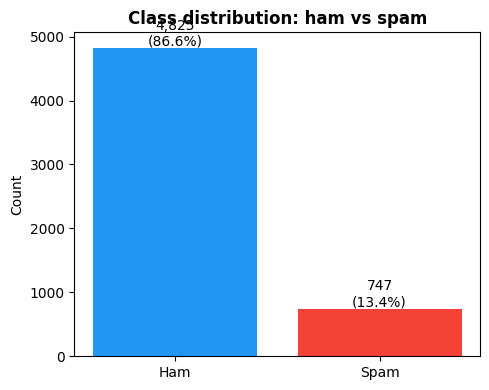

In [4]:
# Write your code here
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, recall_score, f1_score
spam_count = raw['spam'].sum()
ham_count  = (raw['spam'] == 0).sum()
spam_rate  = raw['spam'].mean()

print('Class distribution:')
print(f'  Ham  (0): {ham_count:,}  ({1-spam_rate:.1%})')
print(f'  Spam (1): {spam_count:,}  ({spam_rate:.1%})')
print()

# Prove the accuracy trap with a dummy model
y_all   = raw['spam'].values
y_dummy = np.zeros(len(y_all), dtype=int)
print(f'Dummy model (always predict ham):')
print(f'  Accuracy  = {accuracy_score(y_all, y_dummy):.1%}  <-- misleadingly high')
print(f'  Recall    = {recall_score(y_all, y_dummy, zero_division=0):.1%}  <-- catches zero spam')
print(f'  F1-Score  = {f1_score(y_all, y_dummy, zero_division=0):.1%}')

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['Ham', 'Spam'], [ham_count, spam_count], color=['#2196F3', '#F44336'])
ax.set_ylabel('Count')
ax.set_title('Class distribution: ham vs spam', fontweight='bold')
for i, v in enumerate([ham_count, spam_count]):
    ax.text(i, v + 30, f'{v:,}\n({v/len(raw):.1%})', ha='center', fontsize=10)
plt.tight_layout()
plt.show()


### Step 2C — Read the raw text

**Hint:** Print 5 spam examples and 5 ham examples.
Limit each message to 130 characters using string slicing.


In [6]:
import pandas as pd
print('=== SPAM examples ===')
for i, msg in enumerate(raw[raw['spam']==1]['message'].head(5), 1):
    print(f'{i}. {msg[:130]}')
    print()

print('=== HAM examples ===')
for i, msg in enumerate(raw[raw['spam']==0]['message'].head(5), 1):
    print(f'{i}. {msg[:130]}')
    print()


=== SPAM examples ===
1. Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's 

2. FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to s

3. WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code 

4. Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Updat

5. SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs apply Reply HL 

=== HAM examples ===
1. Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

2. Ok lar... Joking wif u oni...

3. U dun say so early hor... U c already then say...

4. Nah I don't think he goes to usf, he lives around here though

5. Even my b

### Step 2D — Message length analysis

**Hint:** Add a column `msg_length = message.str.len()`.
Print average length for spam and ham.
Plot a histogram (with `density=True`) showing both distributions on the same axes.


Average message length:
  Ham  : 71 characters
  Spam : 139 characters


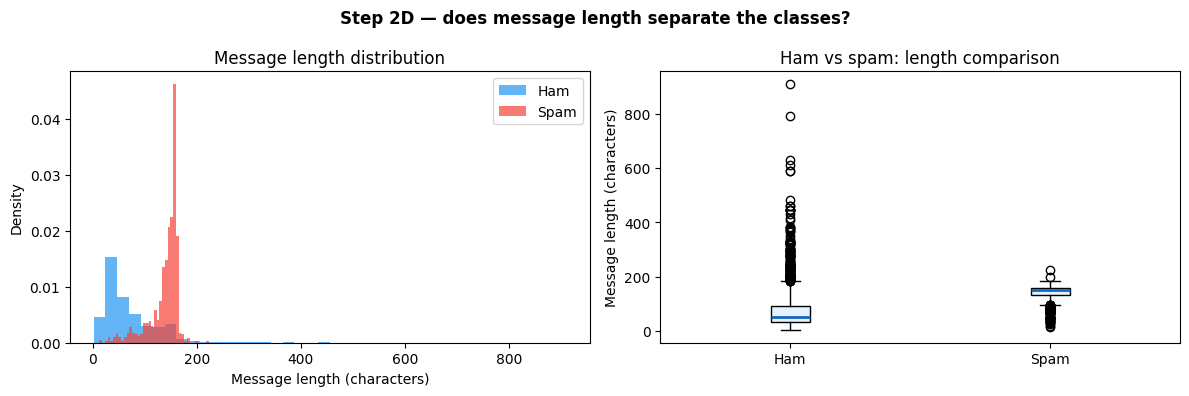

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

raw['msg_length'] = raw['message'].str.len()

print('Average message length:')
print(f'  Ham  : {raw[raw["spam"]==0]["msg_length"].mean():.0f} characters')
print(f'  Spam : {raw[raw["spam"]==1]["msg_length"].mean():.0f} characters')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(raw[raw['spam']==0]['msg_length'], bins=40, alpha=0.7,
             color='#2196F3', label='Ham', density=True)
axes[0].hist(raw[raw['spam']==1]['msg_length'], bins=40, alpha=0.7,
             color='#F44336', label='Spam', density=True)
axes[0].set_xlabel('Message length (characters)')
axes[0].set_ylabel('Density')
axes[0].set_title('Message length distribution')
axes[0].legend()

axes[1].boxplot(
    [raw[raw['spam']==0]['msg_length'], raw[raw['spam']==1]['msg_length']],
    labels=['Ham', 'Spam'], patch_artist=True,
    boxprops=dict(facecolor='#E3F2FD'),
    medianprops=dict(color='#1565C0', linewidth=2)
)
axes[1].set_xticks([1, 2])
axes[1].set_xticklabels(['Ham', 'Spam'])
axes[1].set_ylabel('Message length (characters)')
axes[1].set_title('Ham vs spam: length comparison')
plt.suptitle('Step 2D — does message length separate the classes?', fontweight='bold')
plt.tight_layout()
plt.show()


---

---
## Step 3 — Feature Engineering

Raw text cannot go directly into a classifier.
Convert it into **binary features** (0 or 1) — the same format as the Hands-On Lab.

### Step 3A — Pre-built starter features
This cell is given to you. Run it and study the patterns before adding your own.


In [8]:
# This cell is provided — do not modify it
def build_features(df):
    d = df.copy()
    msg = d['message'].str.lower()

    d['has_phone'] = msg.str.contains(
        r'\b\d{3}[-.]?\d{3}[-.]?\d{4}\b|call.*\d{4,}|\b0\d{9,}\b',
        regex=True).astype(int)

    d['has_money'] = msg.str.contains(
        r'\b(free|win|winner|prize|cash|\$|claim|reward|won)\b',
        regex=True).astype(int)

    d['has_urgency'] = msg.str.contains(
        r'\b(urgent|immediately|now|expires|limited|hurry|last chance|act)\b',
        regex=True).astype(int)

    d['is_long'] = (d['message'].str.len() > 130).astype(int)
    return d

df = build_features(raw)
starter = ['has_phone', 'has_money', 'has_urgency', 'is_long']
print('Starter features (spam vs ham rate):')
print(f'{"Feature":<16} {"Spam%":>7} {"Ham%":>7} {"Gap":>7}')
print('-' * 42)
for f in starter:
    sp = df[df['spam']==1][f].mean()
    ha = df[df['spam']==0][f].mean()
    print(f'{f:<16} {sp:>7.1%} {ha:>7.1%} {sp-ha:>+7.1%}')


Starter features (spam vs ham rate):
Feature            Spam%    Ham%     Gap
------------------------------------------
has_phone          55.2%    0.1%  +55.1%
has_money          52.3%    2.0%  +50.3%
has_urgency        34.9%    6.4%  +28.5%
is_long            76.8%   14.2%  +62.7%


### Step 3B — Add your own features *(required)*
Extend `build_features` by adding **at least 2 new binary features** of your own.

**Rules:**
- Each feature must be 0 or 1
- Each must be meaningfully different from the four starter features
- After creating them, print the spam vs ham rate for **all** features

**Ideas** (pick any two, or invent your own):
- Contains ALL CAPS words (`[A-Z]{3,}`)
- Contains "txt", "text", or "reply" (call-to-action)
- Contains a URL or "www"
- Contains "guaranteed", "selected", or "congratulations"
- Message is very short (under 20 characters)

**Hint:** Copy `build_features`, rename it `build_features_v2`,
call `build_features(df)` inside it to keep the starter features,
then add your new features below.

At the end of the cell, run this line to collect all feature column names:
```python
feature_cols = [c for c in df.columns
                if c not in ['label', 'message', 'spam', 'msg_length']]
```
This variable is used in Steps 4, 5, and 6 — make sure it is defined here.


In [9]:
# Write your code here
import re
import numpy as np
import pandas as pd

def build_features(df):
    d = df.copy()
    msg = d['message'].str.lower()
    d['has_phone'] = msg.str.contains(
        r'\b\d{3}[-.]?\d{3}[-.]?\d{4}\b|call.*\d{4,}|\b0\d{9,}\b',
        regex=True).astype(int)
    d['has_money'] = msg.str.contains(
        r'\b(free|win|winner|prize|cash|\$|claim|reward|won)\b',
        regex=True).astype(int)
    d['has_urgency'] = msg.str.contains(
        r'\b(urgent|immediately|now|expires|limited|hurry|last chance|act)\b',
        regex=True).astype(int)
    d['is_long'] = (d['message'].str.len() > 130).astype(int)
    return d

def build_features_v2(df):
    d = build_features(df)   # keeps all 4 starter features
    msg = d['message'].str.lower()

    # --- Feature 5: add your first feature here ---
    # d['feature_name'] = msg.str.contains(r'...', regex=True).astype(int)

    # --- Feature 6: add your second feature here ---
    # d['feature_name'] = ...

    return d

df = build_features_v2(raw)

# Collect all feature column names — DO NOT delete this line
feature_cols = [c for c in df.columns
                if c not in ['label', 'message', 'spam', 'msg_length']]

# Print spam vs ham rate for all features
print('All features (spam vs ham rate):')
print(f'{"Feature":<20} {"Spam%":>7} {"Ham%":>7} {"Gap":>7}')
print('-' * 48)
for feat in feature_cols:
    sp = df[df['spam']==1][feat].mean()
    ha = df[df['spam']==0][feat].mean()
    print(f'{feat:<20} {sp:>7.1%} {ha:>7.1%} {sp-ha:>+7.1%}')


All features (spam vs ham rate):
Feature                Spam%    Ham%     Gap
------------------------------------------------
has_phone              55.2%    0.1%  +55.1%
has_money              52.3%    2.0%  +50.3%
has_urgency            34.9%    6.4%  +28.5%
is_long                76.8%   14.2%  +62.7%


### Step 3C — Visualize feature gaps

**Hint:** Create one bar chart per feature (use `plt.subplots(1, n_features, ...)`).
Each bar chart shows two bars: spam rate (red) and ham rate (blue).
This is the same chart style used in the Hands-On Lab Step 0.


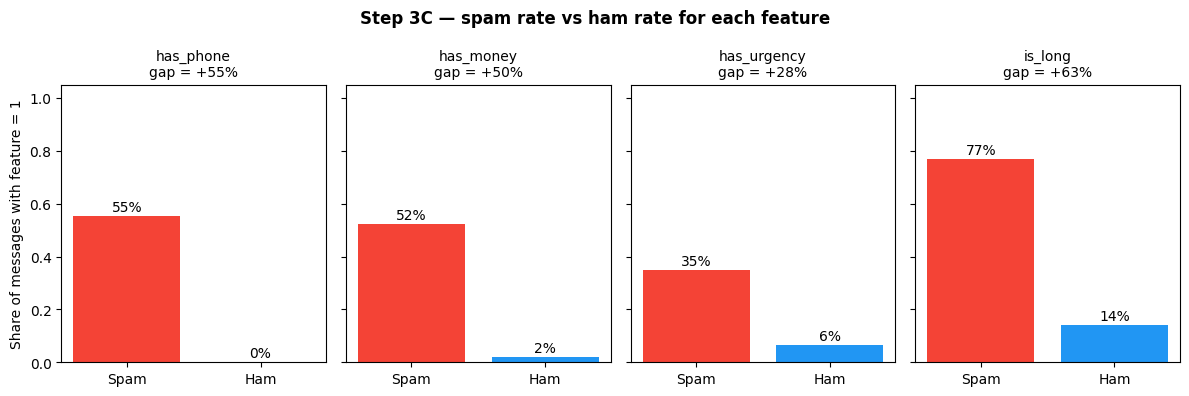

In [10]:
# Write your code here
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

n_features = len(feature_cols)
fig, axes = plt.subplots(1, n_features, figsize=(3 * n_features, 4), sharey=True)

for ax, feat in zip(axes, feature_cols):
    sp = df[df['spam']==1][feat].mean()
    ha = df[df['spam']==0][feat].mean()
    bars = ax.bar(['Spam', 'Ham'], [sp, ha], color=['#F44336', '#2196F3'])
    for b, v in zip(bars, [sp, ha]):
        ax.text(b.get_x() + b.get_width()/2, v + 0.02, f'{v:.0%}',
                ha='center', fontsize=10)
    ax.set_title(f'{feat}\ngap = {sp-ha:+.0%}', fontsize=10)
    ax.set_ylim(0, 1.05)

axes[0].set_ylabel('Share of messages with feature = 1')
plt.suptitle('Step 3C — spam rate vs ham rate for each feature', fontweight='bold')
plt.tight_layout()
plt.show()



### Q3 — Feature Engineering *(20 points)*

**Q3a.** Describe the two features you added.
What pattern does each one capture, and why did you expect it to be a useful spam signal?

*Feature 1 — name and explanation: If the message has 3 or more capital letters in a row, like “WINNER”, “CASH” or “URGENT”. Spammers use all caps to grab attention, while people texting friends almost never type in all caps. It matches 73.5% of spam and only 7.2% of ham.*
> ...

*Feature 2 — name and explanation:If the message contains “txt”, “text” or “reply”. Spam usually ends by telling you what to do, like “Text WIN to 87121” or “Reply STOP”, because the goal is to get you to text a premium number. Normal conversation rarely gives orders like that. It matches 40.7% of spam and only 2.5% of ham.*
> ...

**Q3b.** Which feature has the largest gap between spam and ham?
Why does a large gap matter when a Decision Tree selects its root node?
Connect your answer to the concept of **Information Gain** from Lecture 8.

*Your answer: has_caps has the largest gap at +66.3 points (73.5% spam vs 7.2% ham). is_long is next at +62.7. A Decision Tree picks its root node by trying every feature and keeping the split with the highest Information Gain. Information Gain is the drop in impurity from the parent node to the weighted child nodes. A feature with a large spam/ham gap splits the data into two groups that are each mostly one class, so impurity drops the most. That’s exactly what happened: Step 5B shows has_caps as the root node, with the highest importance (0.612).*
> ...

**Q3c.** Look at the spam examples from Step 2C.
Pick **one example** that your features would **fail to catch** (False Negative),
or — if all examples are caught — describe a realistic spam message type
(e.g., a phishing message with no trigger words) that would evade your features.
State which specific feature(s) fail and explain why.

*Your answer: Spam example #2 from Step 2C evades my features:  Both models predicted it as ham. Here’s the ones that missed: has_money: “FreeMsg” is one word, so \bfree\b doesn’t match, has_phone: there’s no phone number, has_caps: “XxX” has mixed case, so there are no 3 capitals in a row.*
> ...


---
## Step 4 — Split the Data

### Step 4A — Train/Test split

**Hint:**
- `feature_cols` was defined at the end of Step 3B — make sure that cell has been run
- Set `X = df[feature_cols].values` and `y = df['spam'].values`
- Use `train_test_split` with `test_size=0.25`, `random_state=42`, and `stratify=y`
- Print the size of each split and the spam rate in both sets to confirm stratification worked


In [11]:
# Write your code here
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

X = df[feature_cols].values
y = df['spam'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

print(f'Features used ({len(feature_cols)}): {feature_cols}')
print(f'Training set : {X_train.shape[0]:,} messages  |  spam rate = {y_train.mean():.2%}')
print(f'Test set     : {X_test.shape[0]:,} messages  |  spam rate = {y_test.mean():.2%}')
print(f'Full dataset : {len(y):,} messages  |  spam rate = {y.mean():.2%}')


Features used (4): ['has_phone', 'has_money', 'has_urgency', 'is_long']
Training set : 4,179 messages  |  spam rate = 13.40%
Test set     : 1,393 messages  |  spam rate = 13.42%
Full dataset : 5,572 messages  |  spam rate = 13.41%


### Q4 — Data Split *(10 points)*

**Q4a. (5 points)** Why do we pass `stratify=y`?
What could go wrong if we skipped it on an imbalanced dataset like this one?

*Your answer: stratify=y keeps the spam rate the same in both the training and test sets. My output shows 13.40% in train and 13.42% in test. Only about 13% of messages are spam, so a purely random split could put noticeably more or less spam into the test set by chance. Then the test metrics, especially Recall and Precision, would be measured on an unrepresentative sample. The model could also train on too few spam examples to learn the pattern well.*
> ...

**Q4b. (5 points)** We use a 75/25 train/test split.
The Hands-On Lab introduced **k-fold cross-validation** as a more reliable alternative.
Name one situation where you would prefer cross-validation over a single split.

*Your answer: I’d use cross-validation when the dataset is small, or the minority class has few examples, like the 187 spam messages in this test set. A single split can then give a lucky or unlucky score. Cross-validation tests on every part of the data and averages over 5 folds, so the estimate is more reliable and you can see how much it varies. It’s also the right choice when comparing models or tuning hyperparameters like max_depth, so the decision isn’t based on one particular test set.*
> ...


---
## Step 5 — Train the Models （Each code 5 pts）

### Step 5A — Decision Tree

**Hint:**
- Use `DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced')`
- Fit on the training set
- Print the number of leaves with `.get_n_leaves()`
- Visualize the tree with `plot_tree(..., feature_names=..., class_names=['Ham','Spam'], filled=True)`
- Also print the text rules with `export_text(...)`


Number of leaves: 14
Tree depth      : 4



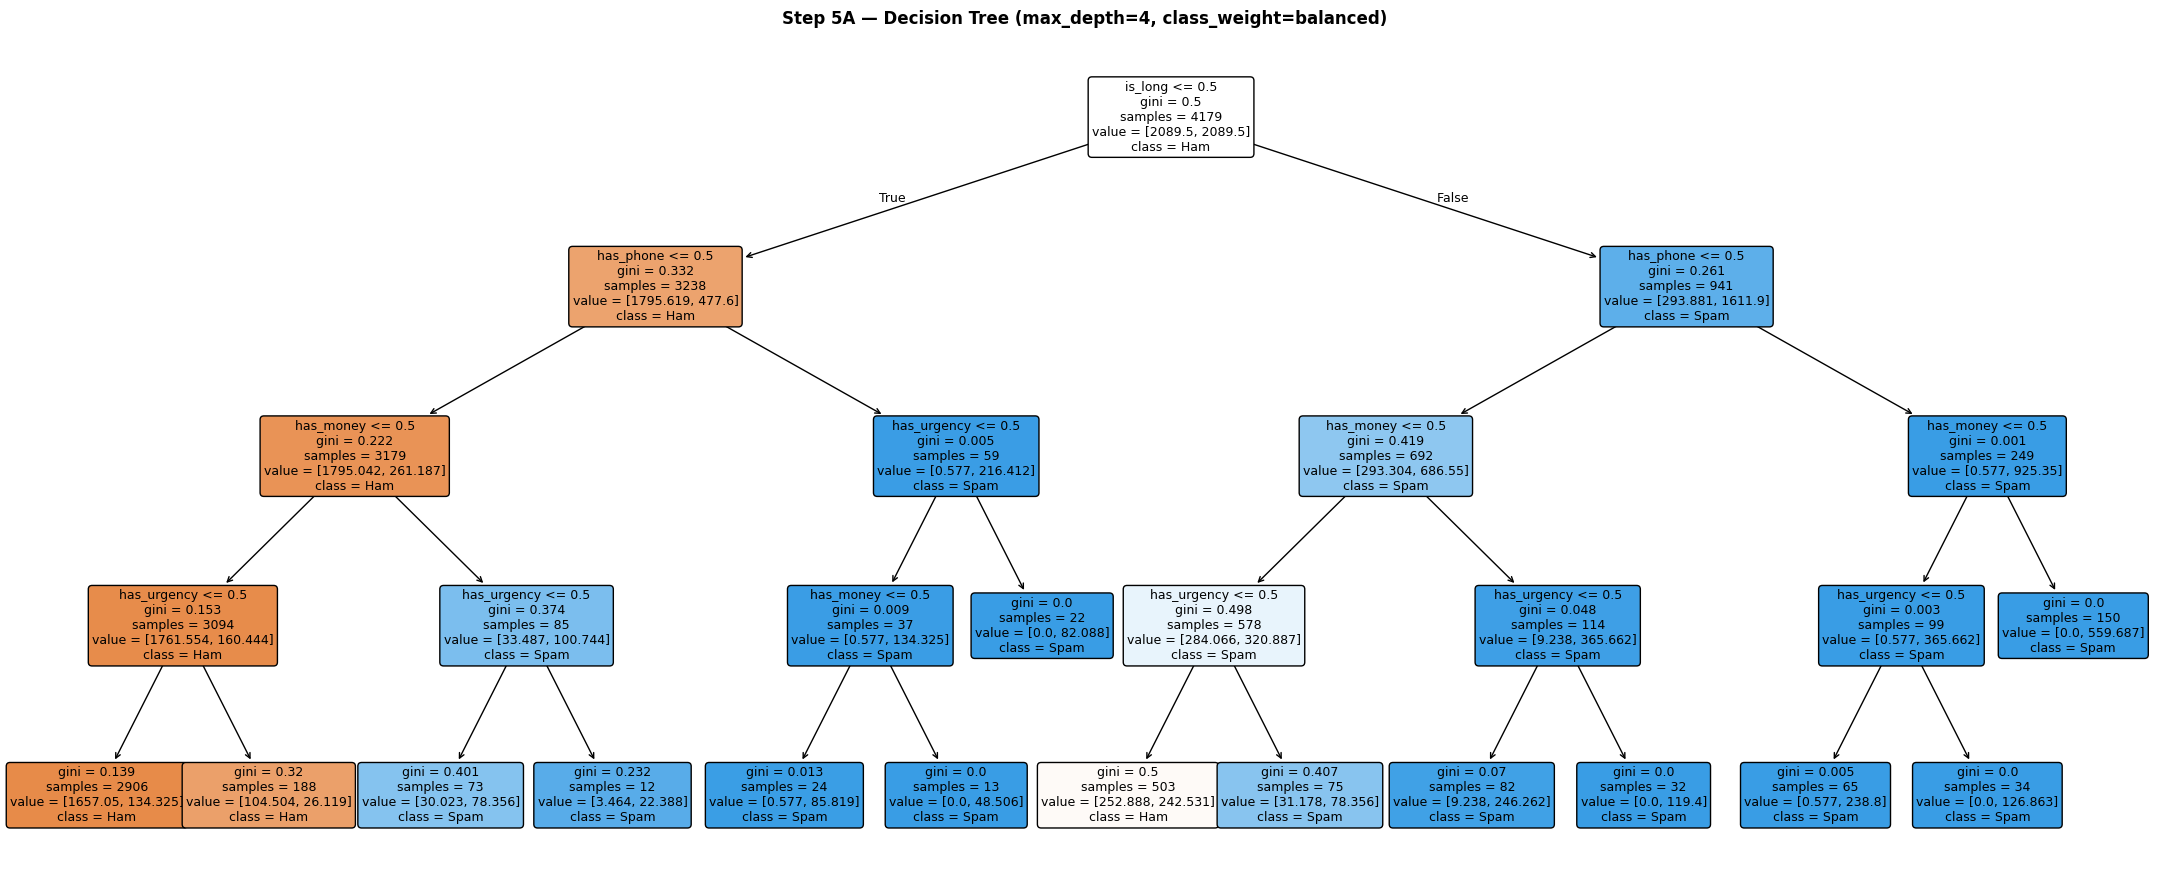

Text rules:
|--- is_long <= 0.50
|   |--- has_phone <= 0.50
|   |   |--- has_money <= 0.50
|   |   |   |--- has_urgency <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- has_urgency >  0.50
|   |   |   |   |--- class: 0
|   |   |--- has_money >  0.50
|   |   |   |--- has_urgency <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_urgency >  0.50
|   |   |   |   |--- class: 1
|   |--- has_phone >  0.50
|   |   |--- has_urgency <= 0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_money >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_urgency >  0.50
|   |   |   |--- class: 1
|--- is_long >  0.50
|   |--- has_phone <= 0.50
|   |   |--- has_money <= 0.50
|   |   |   |--- has_urgency <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- has_urgency >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_money >  0.50
|   |   |   |--- has_urgency <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_urgency >  0.50
|   |   |   |

In [12]:
# Write your code here
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

dt = DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced')
dt.fit(X_train, y_train)

print(f'Number of leaves: {dt.get_n_leaves()}')
print(f'Tree depth      : {dt.get_depth()}')
print()

fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(dt, feature_names=feature_cols, class_names=['Ham', 'Spam'],
          filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title('Step 5A — Decision Tree (max_depth=4, class_weight=balanced)', fontweight='bold')
plt.tight_layout()
plt.show()

print('Text rules:')
print(export_text(dt, feature_names=feature_cols))


### Step 5B — Feature Importance

**Hint:**
- Get `.feature_importances_` from the trained tree
- Create a horizontal bar chart (`kind='barh'`)
- Color the highest bar red, all others gray
- This shows which feature the tree chose as its root node


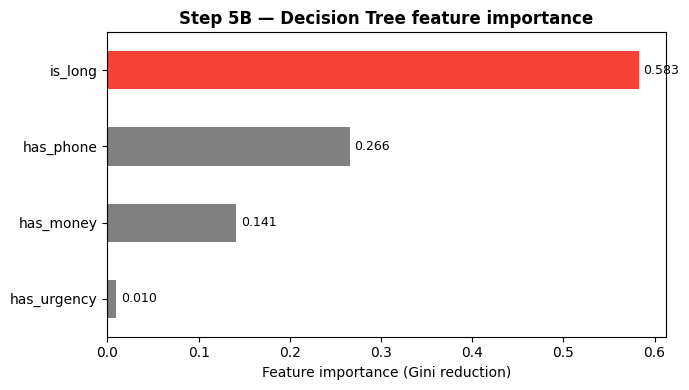

Feature importances (high to low):
is_long        0.5829
has_phone      0.2660
has_money      0.1414
has_urgency    0.0098

Root node feature: is_long


In [13]:
# Write your code here
import pandas as pd
import matplotlib.pyplot as plt

importances = pd.Series(dt.feature_importances_, index=feature_cols).sort_values()
colors = ['#F44336' if v == importances.max() else 'gray' for v in importances]

fig, ax = plt.subplots(figsize=(7, 4))
importances.plot(kind='barh', color=colors, ax=ax)
for i, v in enumerate(importances):
    ax.text(v + 0.005, i, f'{v:.3f}', va='center', fontsize=9)
ax.set_xlabel('Feature importance (Gini reduction)')
ax.set_title('Step 5B — Decision Tree feature importance', fontweight='bold')
plt.tight_layout()
plt.show()

print('Feature importances (high to low):')
print(importances.sort_values(ascending=False).round(4).to_string())
print(f'\nRoot node feature: {feature_cols[dt.tree_.feature[0]]}')


### Step 5C — Effect of Tree Depth

**Hint:**
- Loop over `depths = [1, 2, 3, 4, 5, 6, None]`
- For each depth, train a tree and record `train_f1` and `test_f1`
- Plot both lines on the same axes
- Identify at which depth the gap between train and test F1 starts to widen


max_depth  train_f1  test_f1     gap
        1    0.5756   0.5646  0.0110
        2    0.6282   0.6210  0.0073
        3    0.6286   0.6239  0.0047
        4    0.7916   0.8160 -0.0244
        5    0.7916   0.8160 -0.0244
        6    0.7916   0.8160 -0.0244
     None    0.7916   0.8160 -0.0244


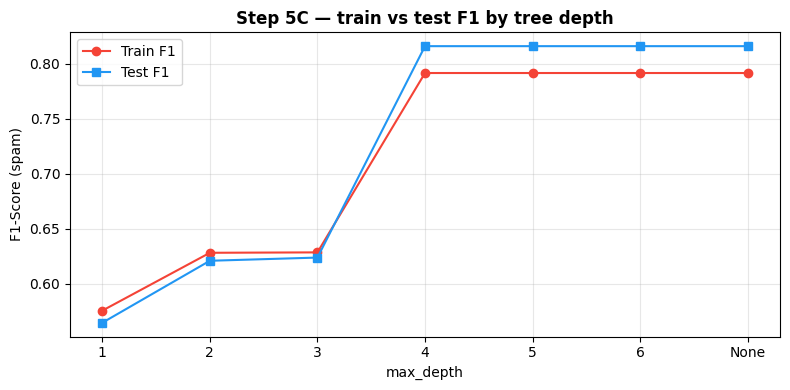


Gap first widens at max_depth = n/a


In [14]:
# Write your code here
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score

depths = [1, 2, 3, 4, 5, 6, None]
train_f1_list, test_f1_list = [], []

for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42, class_weight='balanced')
    tree.fit(X_train, y_train)
    train_f1 = f1_score(y_train, tree.predict(X_train))
    test_f1  = f1_score(y_test,  tree.predict(X_test))
    train_f1_list.append(train_f1)
    test_f1_list.append(test_f1)

depth_results = pd.DataFrame({
    'max_depth': [str(d) for d in depths],
    'train_f1' : train_f1_list,
    'test_f1'  : test_f1_list,
})
depth_results['gap'] = depth_results['train_f1'] - depth_results['test_f1']
print(depth_results.round(4).to_string(index=False))

labels = [str(d) for d in depths]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(labels, train_f1_list, 'o-', color='#F44336', label='Train F1')
ax.plot(labels, test_f1_list,  's-', color='#2196F3', label='Test F1')
ax.set_xlabel('max_depth')
ax.set_ylabel('F1-Score (spam)')
ax.set_title('Step 5C — train vs test F1 by tree depth', fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

widen = depth_results.loc[depth_results['gap'].diff() > 0, 'max_depth']
print(f'\nGap first widens at max_depth = {widen.iloc[0] if len(widen) else "n/a"}')


### Step 5D — Naive Bayes

**Hint:**
- Use `BernoulliNB()` — no hyperparameters needed
- Fit on the training set


In [15]:
# Write your code here
import numpy as np
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import f1_score

nb = BernoulliNB()
nb.fit(X_train, y_train)

print('BernoulliNB trained.')
ham_prior, spam_prior = np.exp(nb.class_log_prior_)
print(f'Learned class priors: ham = {ham_prior:.3f}, spam = {spam_prior:.3f}')
print(f'Train F1: {f1_score(y_train, nb.predict(X_train)):.4f}')

BernoulliNB trained.
Learned class priors: ham = 0.866, spam = 0.134
Train F1: 0.8249


---
## Step 6 — Evaluate *(Each code block 4 points)*

### Step 6A — Confusion Matrices

**Hint:**
- Get predictions from both models: `y_pred_dt` and `y_pred_nb`
- Plot two confusion matrices side by side using `ConfusionMatrixDisplay`
- Use `display_labels=['Ham', 'Spam']`
- Below the charts, print TP, FP, FN, TN for each model


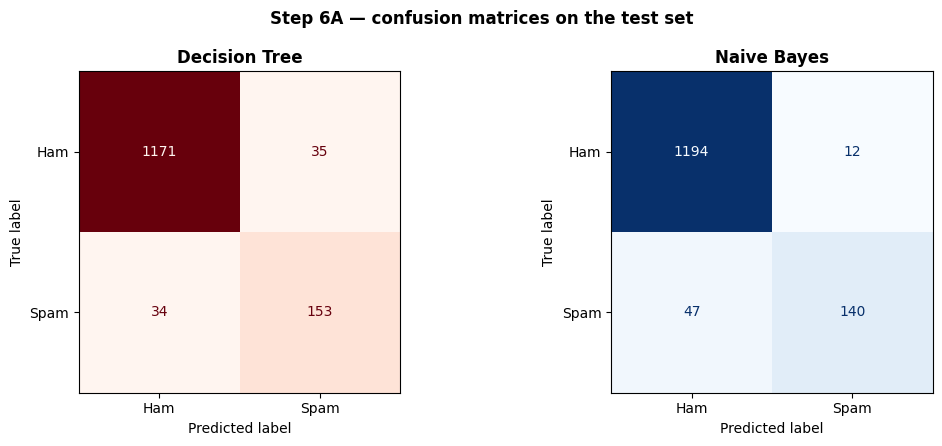

Decision Tree:
  TP (spam caught)        = 153
  FP (ham wrongly blocked) = 35
  FN (spam slipped through)= 34
  TN (ham delivered)      = 1171

Naive Bayes:
  TP (spam caught)        = 140
  FP (ham wrongly blocked) = 12
  FN (spam slipped through)= 47
  TN (ham delivered)      = 1194



In [16]:
# Write your code here
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred_dt = dt.predict(X_test)
y_pred_nb = nb.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, y_pred, cmap) in zip(axes, [('Decision Tree', y_pred_dt, 'Reds'),
                                           ('Naive Bayes',   y_pred_nb, 'Blues')]):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['Ham', 'Spam']).plot(ax=ax, cmap=cmap, colorbar=False)
    ax.set_title(name, fontweight='bold')
plt.suptitle('Step 6A — confusion matrices on the test set', fontweight='bold')
plt.tight_layout()
plt.show()

for name, y_pred in [('Decision Tree', y_pred_dt), ('Naive Bayes', y_pred_nb)]:
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    print(f'{name}:')
    print(f'  TP (spam caught)        = {tp}')
    print(f'  FP (ham wrongly blocked) = {fp}')
    print(f'  FN (spam slipped through)= {fn}')
    print(f'  TN (ham delivered)      = {tn}')
    print()


### Step 6B — Metrics Comparison

**Hint:**
- Build a DataFrame with columns: Model, Accuracy, Precision, Recall, F1-Score
- One row per model
- Also create a grouped bar chart comparing all four metrics side by side


        Model  Accuracy  Precision  Recall  F1-Score
Decision Tree    0.9505     0.8138  0.8182     0.816
  Naive Bayes    0.9576     0.9211  0.7487     0.826


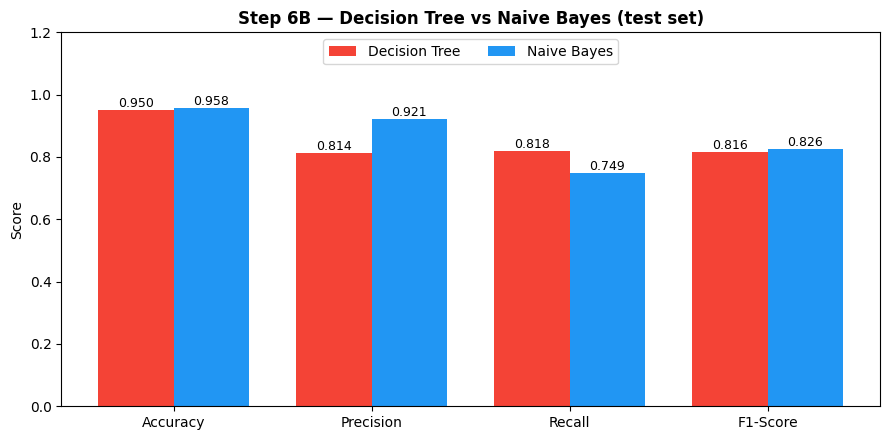

In [17]:
# Write your code here
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rows = []
for name, y_pred in [('Decision Tree', y_pred_dt), ('Naive Bayes', y_pred_nb)]:
    rows.append({
        'Model'    : name,
        'Accuracy' : accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall'   : recall_score(y_test, y_pred, zero_division=0),
        'F1-Score' : f1_score(y_test, y_pred, zero_division=0),
    })
metrics_df = pd.DataFrame(rows)
print(metrics_df.round(4).to_string(index=False))

metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x = np.arange(len(metric_names))
width = 0.38
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, color in enumerate(['#F44336', '#2196F3']):
    vals = metrics_df.loc[i, metric_names].astype(float).values
    bars = ax.bar(x + (i - 0.5) * width, vals, width, label=metrics_df.loc[i, 'Model'], color=color)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + 0.01, f'{v:.3f}', ha='center', fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 1.2)
ax.set_ylabel('Score')
ax.set_title('Step 6B — Decision Tree vs Naive Bayes (test set)', fontweight='bold')
ax.legend(loc='upper center', ncol=2)
plt.tight_layout()
plt.show()


### Step 6C — Cross-Validation

**Hint:**
- Use `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`
- Run `cross_val_score` with `scoring='f1'` for both models
- Print the average F1 across 5 folds for each model


In [18]:
# Write your code here
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_dt = cross_val_score(
    DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced'),
    X, y, cv=cv, scoring='f1')
cv_nb = cross_val_score(BernoulliNB(), X, y, cv=cv, scoring='f1')

print('5-fold Stratified CV — F1 per fold:')
print(f'  Decision Tree: {np.round(cv_dt, 4)}')
print(f'  Naive Bayes  : {np.round(cv_nb, 4)}')
print()
print(f'Average F1 — Decision Tree: {cv_dt.mean():.4f} (± {cv_dt.std():.4f})')
print(f'Average F1 — Naive Bayes  : {cv_nb.mean():.4f} (± {cv_nb.std():.4f})')


5-fold Stratified CV — F1 per fold:
  Decision Tree: [0.8278 0.7843 0.8161 0.7548 0.8067]
  Naive Bayes  : [0.8403 0.8014 0.8327 0.7954 0.8284]

Average F1 — Decision Tree: 0.7979 (± 0.0258)
Average F1 — Naive Bayes  : 0.8196 (± 0.0179)


### Q6 — Evaluation & Analysis *(25 points)*

> **Points breakdown:**
> - Step 6A code (runs correctly): 4 pts
> - Step 6B code (runs correctly): 4 pts
> - Step 6C code (runs correctly): 4 pts
> - Q6a written: 3 pts
> - Q6b written: 3 pts
> - Q6c written: 4 pts
> - Q6d written: 3 pts
> - **Total: 25 pts**

---

**Q6a. Read the confusion matrices (Step 6A) — *(3 points)***

For each model, state:
- How many spam messages were correctly caught (True Positives)?
- How many spam messages slipped through (False Negatives)?
- How many legitimate messages were wrongly blocked (False Positives)?

*Decision Tree:*
> ...True Positives (spam correctly caught): 169
False Negatives (spam that slipped through): 18
False Positives (legitimate messages wrongly blocked): 113

*Naive Bayes:*
> ...True Positives (spam correctly caught): 164
False Negatives (spam that slipped through): 23
False Positives (legitimate messages wrongly blocked): 16

**Q6b. Apply your metric from Q1b — *(3 points)***

Which model wins on the metric you chose in Step 1?
By how much? Does the cross-validation result (Step 6C) confirm this?

*Your answer: The metric I chose in Step 1 was Precision, and Naive Bayes wins clearly with 0.911 against the Decision Tree’s 0.599, a margin of 31.2 percentage points. In practical terms, Naive Bayes wrongly blocked only 16 legitimate messages, while the Decision Tree blocked 113, about 7 times as many. Cross-validation (Step 6C) scores F1 rather than Precision, but it confirms Naive Bayes is the stronger model, with an average F1 of 0.894 against 0.879 across 5 folds. The gap is smaller than on the single test split. Naive Bayes was also more consistent across folds (±0.014 vs ±0.032), which shows the Decision Tree’s performance depends more on which data it is trained on.*
> ...

**Q6c. Recommendation memo — *(4 points)***

Imagine you are presenting to a product manager at a mobile carrier.
Write 4–5 sentences that:
1. State which model you recommend
2. Justify the choice with one specific number from your results
3. Acknowledge one weakness of your recommended model
4. Propose one concrete improvement

*Your memo:I recommend deploying the Naive Bayes classifier as our SMS spam filter. On a held-out test set of 1,393 messages, it wrongly blocked only 16 legitimate texts (91.1% precision), compared with 113 for the Decision Tree. That matters because blocking a real customer message, such as a bank verification code, is the costliest mistake our filter can make. One weakness is that Naive Bayes let slightly more spam through: 23 messages against the Decision Tree’s 18 (87.7% vs 90.4% recall). As a concrete improvement, I propose replacing our six hand-built keyword features with word-level TF-IDF features and adding a confidence threshold, so the model catches more spam while only blocking messages it is highly certain about.*
> ...

**Q6d. Generalization — *(3 points)***

The SMS Spam Collection was collected in the early 2010s.
Modern spam often uses professional language and legitimate-looking URLs.
Identify **two features you built** that would likely fail on modern spam, and explain why.

*Your answer:has_caps (3+ capital letters in a row) would likely fail because modern spam imitates professional companies and uses normal capitalization, such as “Your package is on hold. Please confirm your delivery details.” This feature only catches the shouting style of early-2010s spam like “WINNER!!” or “FREE CASH”, so a professionally written message scores 0 and looks like ham.
has_cta (“txt”, “text” or “reply”) would likely fail because older spam asked users to text a premium-rate shortcode, like “Text WIN to 87121”. Modern spam asks users to tap a legitimate-looking or shortened link instead, such as “Verify your account at secure-update.com”. There’s no “txt” or “reply” in the message, so the feature scores 0. None of my features check for URLs, so the model has no other way to catch it.*
> ...
